In [234]:
# đây là bài fruit classification

In [235]:
ROOT = "../data/raw"
TRAIN_DIR = ROOT + "/train"
TEST_DIR = ROOT + "/test"
IMG_SIZE = 224
# lấy tên file trong thư mục
import os

fruit_names = os.listdir(TRAIN_DIR)

print(fruit_names)
print(f"có {len(fruit_names)} thư mục con trong thư mục {TRAIN_DIR}")
print(f"có {len(os.listdir(TEST_DIR))} thư mục con trong thư mục {TEST_DIR}")

['apple', 'avocado', 'banana', 'cherry', 'kiwi', 'mango', 'orange', 'pinenapple', 'strawberries', 'watermelon']
có 10 thư mục con trong thư mục ../data/raw/train
có 10 thư mục con trong thư mục ../data/raw/test


In [236]:
# thống kê số lượng ảnh trong mỗi fruit class

import pandas as pd


data_pd = pd.DataFrame(fruit_names, columns=["fruit_name"])
data_pd["train_count"] = 0
data_pd["test_count"] = 0
num_images_train = []
num_images_test = []
for folder in fruit_names:
    folder_path = os.path.join(TRAIN_DIR, folder)
    num_images = len(os.listdir(folder_path))
    num_images_train.append(num_images)
    folder_path_test = os.path.join(TEST_DIR, folder)
    num_images_test.append(len(os.listdir(folder_path_test)))
data_pd["train_count"] = num_images_train
data_pd["test_count"] = num_images_test
   

display(data_pd)

,fruit_name,train_count,test_count
0,apple,230,89
1,avocado,230,105
2,banana,230,105
3,cherry,230,105
4,kiwi,230,105
5,mango,231,105
6,orange,227,97
7,pinenapple,230,105
8,strawberries,230,103
9,watermelon,230,105


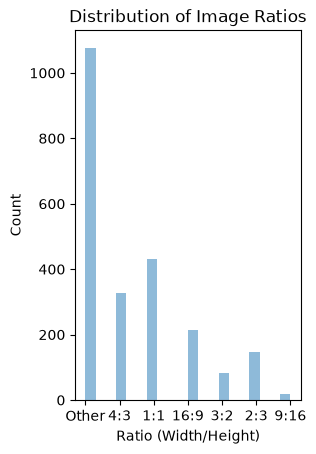

In [237]:
# vẽ biểu đồ đánh giá tỉ lệ width và height của ảnh trong dataset


from collections import Counter
import random
import matplotlib.pyplot as plt

widths = []
heights = []
for folder in fruit_names:
    folder_path = os.path.join(TRAIN_DIR, folder)
    images = os.listdir(folder_path)
    for image_file in images:
        image_path = os.path.join(folder_path, image_file)
        image = plt.imread(image_path)
        widths.append(image.shape[1])
        heights.append(image.shape[0])

ratios = [w / h for w, h in zip(widths, heights)]

# gom nhóm về các tỉ lệ phổ biến như 1:1, 4:3, 16:9, 3:2, 2:3, 9:16

def get_common_ratio_label(ratio):
    if 0.9 <= ratio <= 1.1:
        return "1:1"
    elif 1.3 <= ratio <= 1.4:
        return "4:3"
    elif 1.7 <= ratio <= 1.8:
        return "16:9"
    elif 1.4 <= ratio <= 1.5:
        return "3:2"
    elif 0.6 <= ratio <= 0.7:
        return "2:3"
    elif 0.5 <= ratio <= 0.6:
        return "9:16"
    else:
        return "Other"
    
common_ratio_labels = [get_common_ratio_label(r) for r in ratios]

plt.subplot(1, 2, 2)
plt.hist(common_ratio_labels, bins=20, alpha=0.5)
plt.title('Distribution of Image Ratios')
plt.xlabel('Ratio (Width/Height)')
plt.ylabel('Count')
plt.show()


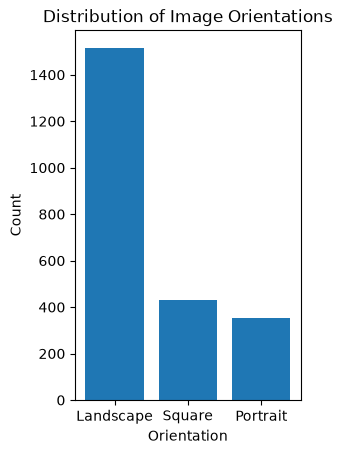

In [238]:
# số lượng ảnh ngang, dọc, vuông trong dataset
orientation_counts = Counter()

for ratio in ratios:
    if ratio > 1.1:
        orientation_counts['Landscape'] += 1
    elif ratio < 0.9:
        orientation_counts['Portrait'] += 1
    else:
        orientation_counts['Square'] += 1
        
plt.subplot(1, 2, 2)
plt.bar(orientation_counts.keys(), orientation_counts.values())
plt.title('Distribution of Image Orientations')
plt.xlabel('Orientation')
plt.ylabel('Count')
plt.show()

In [239]:
# check kênh màu xem có ko phải là RGB không

error_pd = pd.DataFrame(columns=["folder", "image_file"])

error_images = []
error_types = []
def check_error_images(folder_path, image_files):
    for image_file in image_files:
        image_path = os.path.join(folder_path, image_file)
        image = plt.imread(image_path)
        result = ""
        if (image.shape[0]) < 32 or (image.shape[1]) < 32:
            result += "ảnh quá nhỏ "
        if len(image.shape) != 3:
            result += "ảnh 2 chiều"
        if image.shape[2] != 3:
            if image.shape[2] == 4:
                result += "ảnh có alpha channel"
            if image.shape[2] == 1:
                result += "ảnh grayscale"
        return result

for name in fruit_names:
    train_name = os.path.join(TRAIN_DIR, name)
    test_name = os.path.join(TEST_DIR, name)
    images_train = os.listdir(train_name)
    images_test = os.listdir(test_name)
    for image_file in images_train:
        name_error = check_error_images(train_name, [image_file])
        if name_error != "":
            error_types.append(name_error)
            error_images.append((train_name, image_file))
    
    for image_file in images_test:
        name_error = check_error_images(test_name, [image_file])
        if name_error != "":
            error_types.append(name_error)
            error_images.append((test_name, image_file))

error_pd = pd.DataFrame(error_images, columns=["folder", "image_file"])
error_pd["error_type"] = error_types
print(f"Số lượng ảnh lỗi (không phải RGB): {len(error_images)}")
print("Danh sách ảnh lỗi:")
display(error_pd)

Số lượng ảnh lỗi (không phải RGB): 25
Danh sách ảnh lỗi:


,folder,image_file,error_type
0,../data/raw/train\apple,img_4801.jpeg,ảnh có alpha channel
1,../data/raw/train\apple,img_501.jpeg,ảnh có alpha channel
2,../data/raw/train\apple,img_5301.jpeg,ảnh có alpha channel
3,../data/raw/test\apple,img_101.jpeg,ảnh có alpha channel
4,../data/raw/test\apple,img_271.jpeg,ảnh có alpha channel
5,../data/raw/test\apple,img_441.jpeg,ảnh có alpha channel
6,../data/raw/test\avocado,img_591.jpeg,ảnh có alpha channel
7,../data/raw/train\banana,img_1501.jpeg,ảnh có alpha channel
8,../data/raw/train\banana,img_1521.jpeg,ảnh có alpha channel
9,../data/raw/test\banana,img_371.jpeg,ảnh có alpha channel


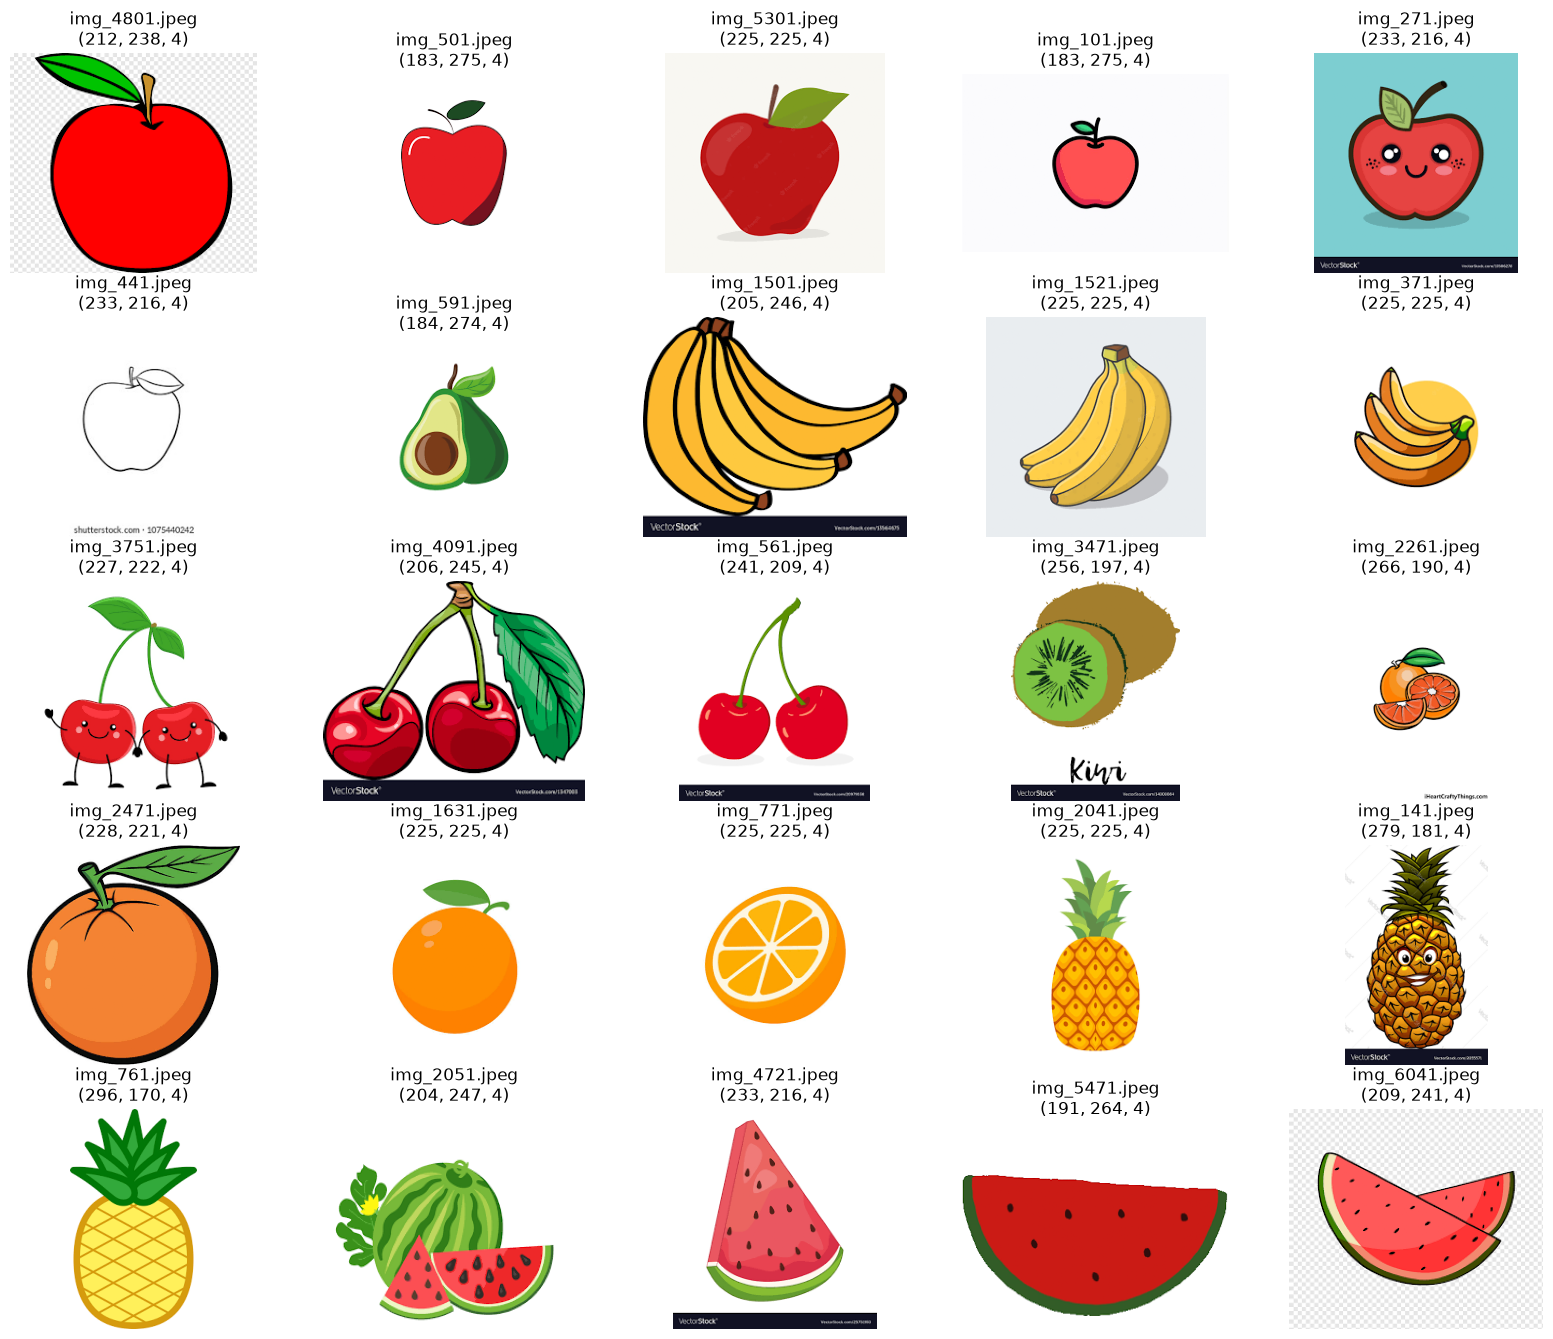

In [240]:
# hiển thị ảnh lỗi(có 16 ảnh)

from math import sqrt

plt.figure(figsize=(20, 20))
for i, (folder, image_file) in enumerate(error_images):
    image_path = os.path.join(folder, image_file)
    image = plt.imread(image_path)
    plt.subplot(int(sqrt(len(error_images))) + 1, int(sqrt(len(error_images))), i + 1)
    plt.imshow(image)
    # định dạng của ảnh lỗi
    plt.title(f"{image_file}\n{image.shape}")
    plt.axis('off')

In [241]:
# hiển thị 5 ảnh ngãu nhiên trong mỗi thư mục ( 10 loại trái cây)


# for folder in file_names:
#     folder_path = os.path.join(TRAIN_DIR, folder)
#     images = os.listdir(folder_path)
#     random_images = random.sample(images, 5)
    
#     plt.figure(figsize=(15, 5))
#     for i, image in enumerate(random_images):
#         img_path = os.path.join(folder_path, image)
#         img = plt.imread(img_path)
#         plt.subplot(1, 5, i + 1)
#         plt.imshow(img)
#         plt.axis('off')
#         plt.title(folder)
#     plt.show()

In [242]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [243]:
# change stucture of model
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(SimpleCNN, self).__init__()
        
        # Block 1: Conv -> ReLU -> MaxPool
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Block 2: Conv -> ReLU -> MaxPool
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        
        # Linear
        self.fc1 = nn.Linear(in_features=64 * (IMG_SIZE//4) * (IMG_SIZE//4), out_features=128)
        self.fc2 = nn.Linear(in_features=128, out_features=num_classes)

        # Global Average Pooling layer to reduce the spatial dimensions
        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()
        
        # dropout layer to prevent overfitting
        # self.dropout = nn.Dropout(p=0.5)
        
        
    def forward(self, x):
        # Block 1
        x = self.pool(F.relu(self.conv1(x)))
        
        # Block 2
        x = self.pool(F.relu(self.conv2(x)))
        
        # Global Average Pooling
        # x = self.global_avg_pool(x)
        
        # Classifier
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        # x = self.dropout(x)
        x = self.fc2(x) # Không cần softmax ở đây vì PyTorch CrossEntropyLoss đã tích hợp sẵn
        
        return x

In [244]:
# import torch
# import torch.nn as nn
# from torchvision import models

# class SimpleCNN(nn.Module):
#     def __init__(self, num_classes=10, freeze_backbone=True):
#         super().__init__()
        
#         # Load ResNet18 pretrained
#         self.backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        
#         # Đóng băng backbone (chỉ train phần classifier trước)
#         if freeze_backbone:
#             for param in self.backbone.parameters():
#                 param.requires_grad = False
        
#         # Thay đổi fully connected cuối
#         in_features = self.backbone.fc.in_features  # 512
#         self.backbone.fc = nn.Sequential(
#             nn.Dropout(0.4),
#             nn.Linear(in_features, num_classes)
#         )
    
#     def forward(self, x):
#         return self.backbone(x)

In [245]:
# Kiểm tra GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
# Khởi tạo model
num_classes = 10 # Thay đổi theo bài toán của bạn
model = SimpleCNN(num_classes=num_classes).to(device)

# tăng trọng số cho class 5
class_weights = torch.ones(num_classes)
class_weights[5] = 2.0  # Tăng trọng số cho class 5
class_weights[6] = 1.5  # Tăng trọng số cho class 6
class_weights = class_weights.to(device)

# Loss và Optimizer
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=0.001)


# Test thử một forward pass với ảnh giả định (Batch_size=4, 3 channels, 64x64)
dummy_input = torch.randn(4, 3, IMG_SIZE, IMG_SIZE).to(device)
output = model(dummy_input)
print(f"Input shape: {dummy_input.shape}")
print(f"Output shape: {output.shape}") # Kỳ vọng: [4, 10]

Using device: cuda
Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 10])


In [246]:
# dataloaders, training loop, validation loop, and evaluation metrics would be implemented here.

from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image


class FruitDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(os.listdir(root_dir))}
        
        for cls_name, idx in self.class_to_idx.items():
            cls_folder = os.path.join(root_dir, cls_name)
            for img_name in os.listdir(cls_folder):
                self.image_paths.append(os.path.join(cls_folder, img_name))
                self.labels.append(idx)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')  # Mặc định chuyển sang RGB

        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label
    

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# chia dataset thành train và validation
from sklearn.model_selection import train_test_split

train = FruitDataset(root_dir=TRAIN_DIR, transform=transform)
test = FruitDataset(root_dir=TEST_DIR, transform=transform)

In [247]:
# dataloaders
train_loader = DataLoader(train, batch_size=32, shuffle=True)
test_loader = DataLoader(test, batch_size=32, shuffle=False)

print(f"Số lượng ảnh trong tập train: {len(train)}")
print(f"Số lượng ảnh trong tập test: {len(test)}")

Số lượng ảnh trong tập train: 2298
Số lượng ảnh trong tập test: 1024


In [248]:
# check dataloader
# import matplotlib.pyplot as plt

# # Create a DataLoader
# train_loader = DataLoader(train, batch_size=32, shuffle=True)

# # Visualize a few images from the DataLoader
# def show_images(dataloader, num_images=5):
#     for images, labels in dataloader:
#         for i in range(num_images):
#             plt.subplot(1, num_images, i + 1)
#             plt.imshow(images[i].permute(1, 2, 0))
#             plt.title(f'Label: {labels[i]}')
#             plt.axis('off')
#         plt.show()
#         break

# show_images(train_loader)

In [249]:
model.eval()

SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=200704, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (global_avg_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (flatten): Flatten(start_dim=1, end_dim=-1)
)

In [250]:
#training loop và test loop
from IPython.display import clear_output
from IPython.display import display
print("Starting training...")

# bảng thống kê loss và accuracy theo epoch

results = pd.DataFrame(columns=["epoch", "train_loss", "val_loss","train_accuracy", "val_accuracy"])
epochs = []
train_losses = []
val_losses = []
val_accuracies = []
train_accuracies = []
display_handle = display(results, display_id=True)

for epoch in range(20):
    model.train()
    running_loss = 0.0
    train_correct = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
    
    train_accuracy = train_correct / len(train_loader.dataset)
    train_accuracies.append(train_accuracy)
    epoch_loss = running_loss / len(train_loader.dataset)
    epochs.append(epoch+1)
    train_losses.append(epoch_loss)
    # print(f"Epoch {epoch+1}, Training Loss: {epoch_loss:.4f}")
    
    # Validation loop
    model.eval()
    val_loss = 0.0
    correct = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
    
    val_epoch_loss = val_loss / len(test_loader.dataset)
    val_accuracy = correct / len(test_loader.dataset)
    # print(f"Epoch {epoch+1}, Validation Loss: {val_epoch_loss:.4f}, Accuracy: {val_accuracy:.4f}")
    val_losses.append(val_epoch_loss)
    val_accuracies.append(val_accuracy)
    results = pd.DataFrame({
        "epoch": epochs,
        "train_loss": train_losses,
        "val_loss": val_losses,
        "train_accuracy": train_accuracies,
        "val_accuracy": val_accuracies
    })
    
    display_handle.update(results)

Starting training...


,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,2.411966,1.720128,0.202785,0.330078
1,2,1.499664,1.456083,0.432115,0.456055
2,3,1.295637,1.429819,0.523934,0.511719
3,4,1.126581,1.435403,0.579199,0.535156
4,5,1.020817,1.226608,0.620540,0.598633
5,6,0.883325,1.262326,0.673194,0.574219
6,7,0.758024,1.206261,0.732376,0.612305
7,8,0.608291,1.330256,0.784160,0.591797
8,9,0.546337,1.220919,0.801131,0.618164
9,10,0.455167,1.456181,0.842472,0.597656


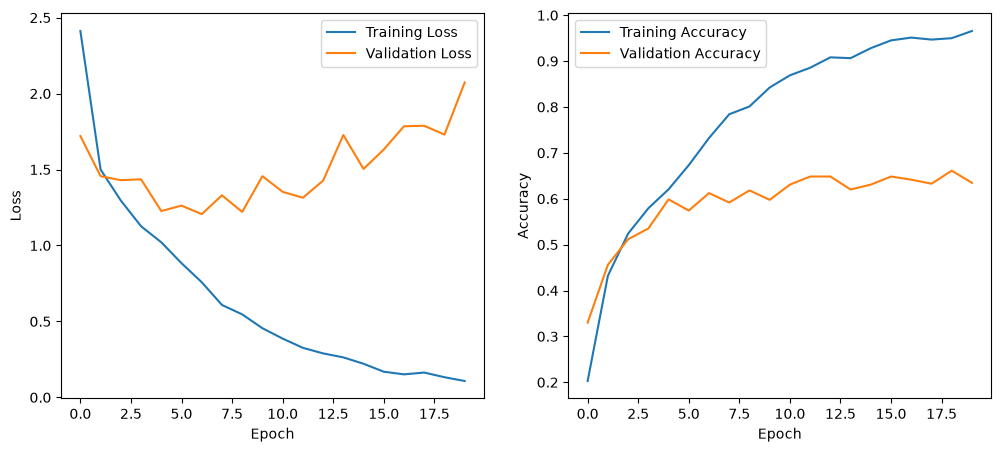

In [251]:
# biểu đồ loss và accuracy theo epoch, dùng results dataframe để vẽ biểu đồ loss và accuracy theo epoch
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(results['train_loss'], label='Training Loss')
plt.plot(results['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(results['train_accuracy'], label='Training Accuracy')
plt.plot(results['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.622571].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.622571].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5528543].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..1.6932774].
Clipping 

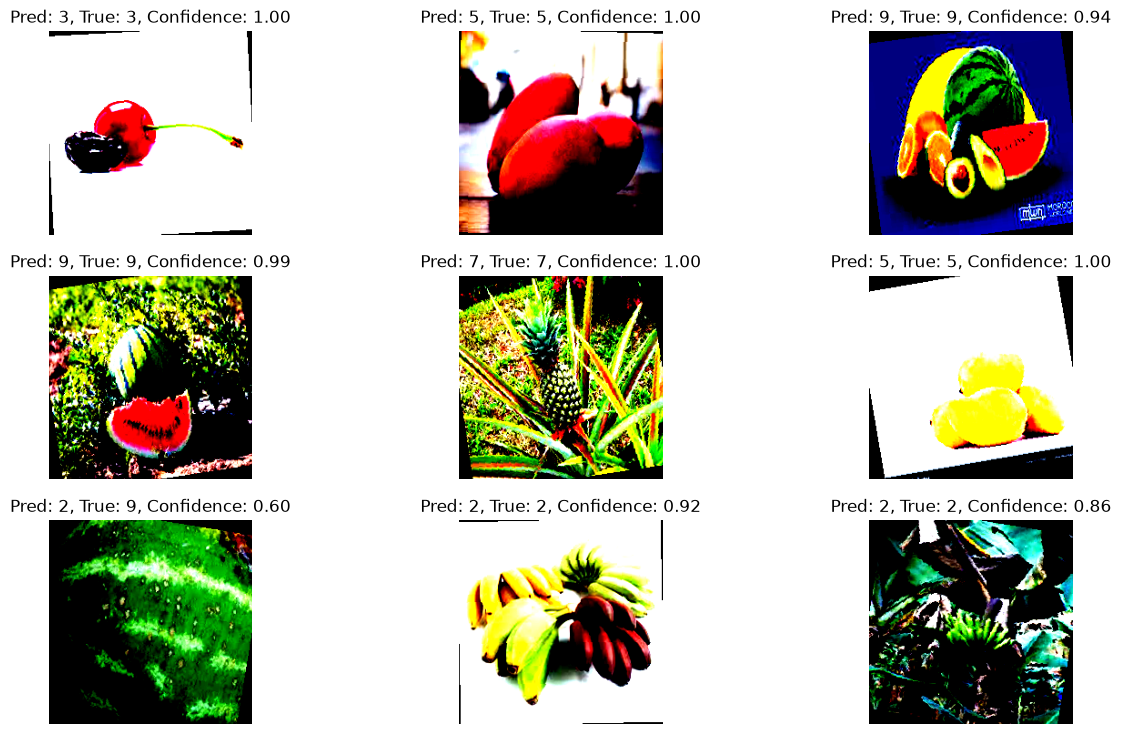

In [252]:
# hiển thị 10 predict trên train và test dataset
plt.figure(figsize=(15, 9))


imgs, labels = next(iter(train_loader))
imgs, labels = imgs.to(device), labels.to(device)
with torch.no_grad():
    outputs = model(imgs)
    _, preds = torch.max(outputs, 1)
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imgs[i].cpu().permute(1, 2, 0))
        # thêm độ tin cậy vào title
        plt.title(f'Pred: {preds[i].item()}, True: {labels[i].item()}, Confidence: {F.softmax(outputs[i], dim=0)[preds[i]].item():.2f}')
        plt.axis('off')


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.3611329].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2489083].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input da

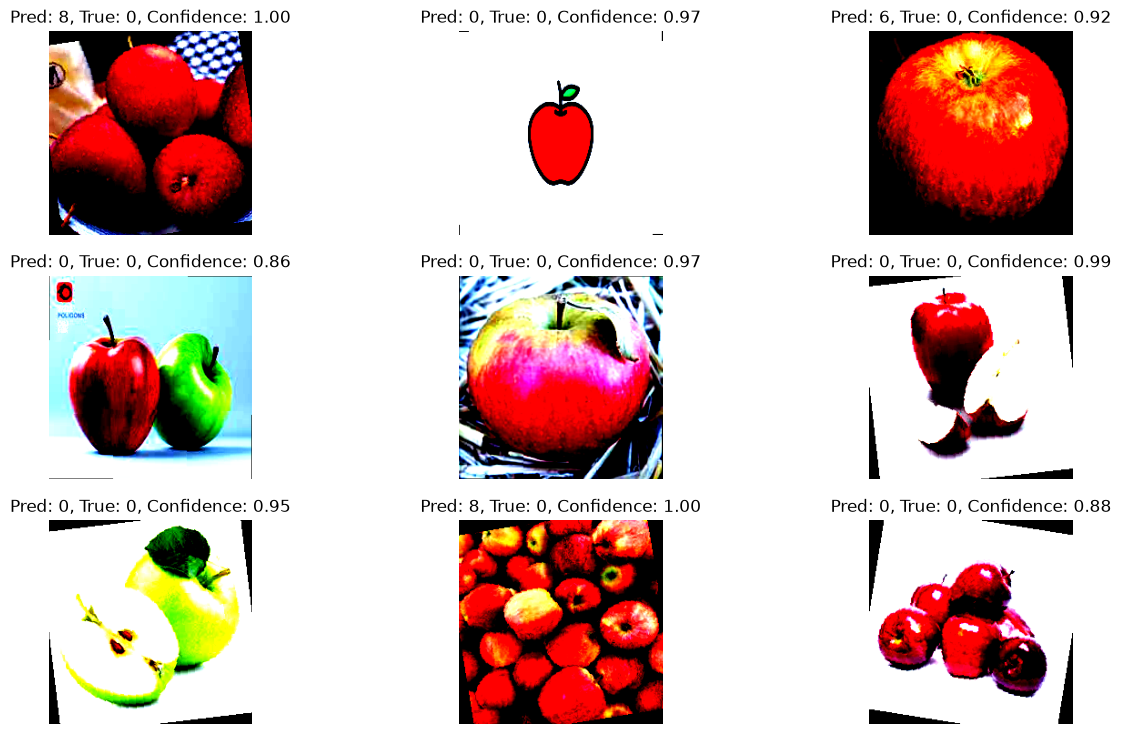

In [253]:
# hiển thị 10 predict trên train và test dataset
plt.figure(figsize=(15, 9))

# test_loader = DataLoader(test, batch_size=32, shuffle=True)

imgs, labels = next(iter(test_loader))
imgs, labels = imgs.to(device), labels.to(device)
with torch.no_grad():
    outputs = model(imgs)
    _, preds = torch.max(outputs, 1)
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imgs[i].cpu().permute(1, 2, 0))
        # thêm độ tin cậy vào title
        plt.title(f'Pred: {preds[i].item()}, True: {labels[i].item()}, Confidence: {F.softmax(outputs[i], dim=0)[preds[i]].item():.2f}')
        plt.axis('off')


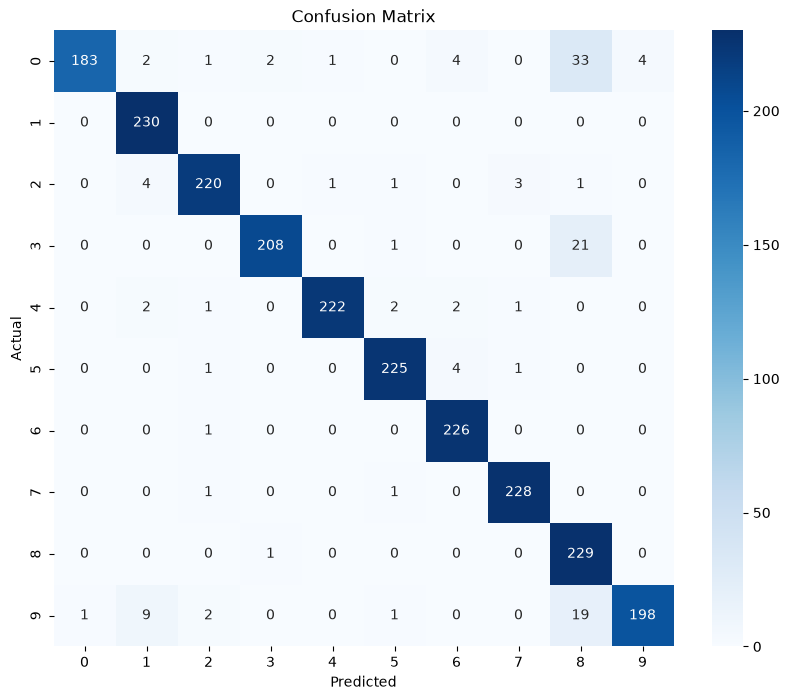

In [254]:
# matrix confusion
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels_list = []
preds_list = []
images_list = []
# độ tin cậy của dự đoán
confidence_list = []

for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)
    with torch.no_grad():
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        confidence, preds = torch.max(probs, 1)
        images_list.extend(images.cpu().numpy())
        labels_list.extend(labels.cpu().numpy())
        preds_list.extend(preds.cpu().numpy())
        confidence_list.extend(confidence.cpu().numpy())
        
cm = confusion_matrix(labels_list, preds_list)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

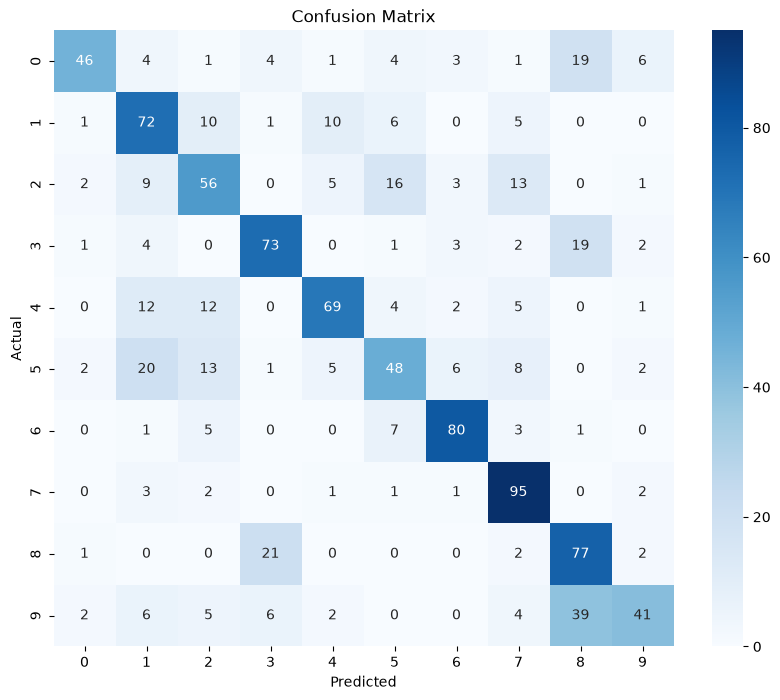

In [255]:
# matrix confusion
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels_list = []
preds_list = []
images_list = []
# độ tin cậy của dự đoán
confidence_list = []

for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)
    with torch.no_grad():
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        confidence, preds = torch.max(probs, 1)
        images_list.extend(images.cpu().numpy())
        labels_list.extend(labels.cpu().numpy())
        preds_list.extend(preds.cpu().numpy())
        confidence_list.extend(confidence.cpu().numpy())
        
cm = confusion_matrix(labels_list, preds_list)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2489083].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.622571].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.3235295].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2710083].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.535425].
Clip

Số lượng ảnh dự đoán sai của class 5: 57


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5005665].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2489083].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input da

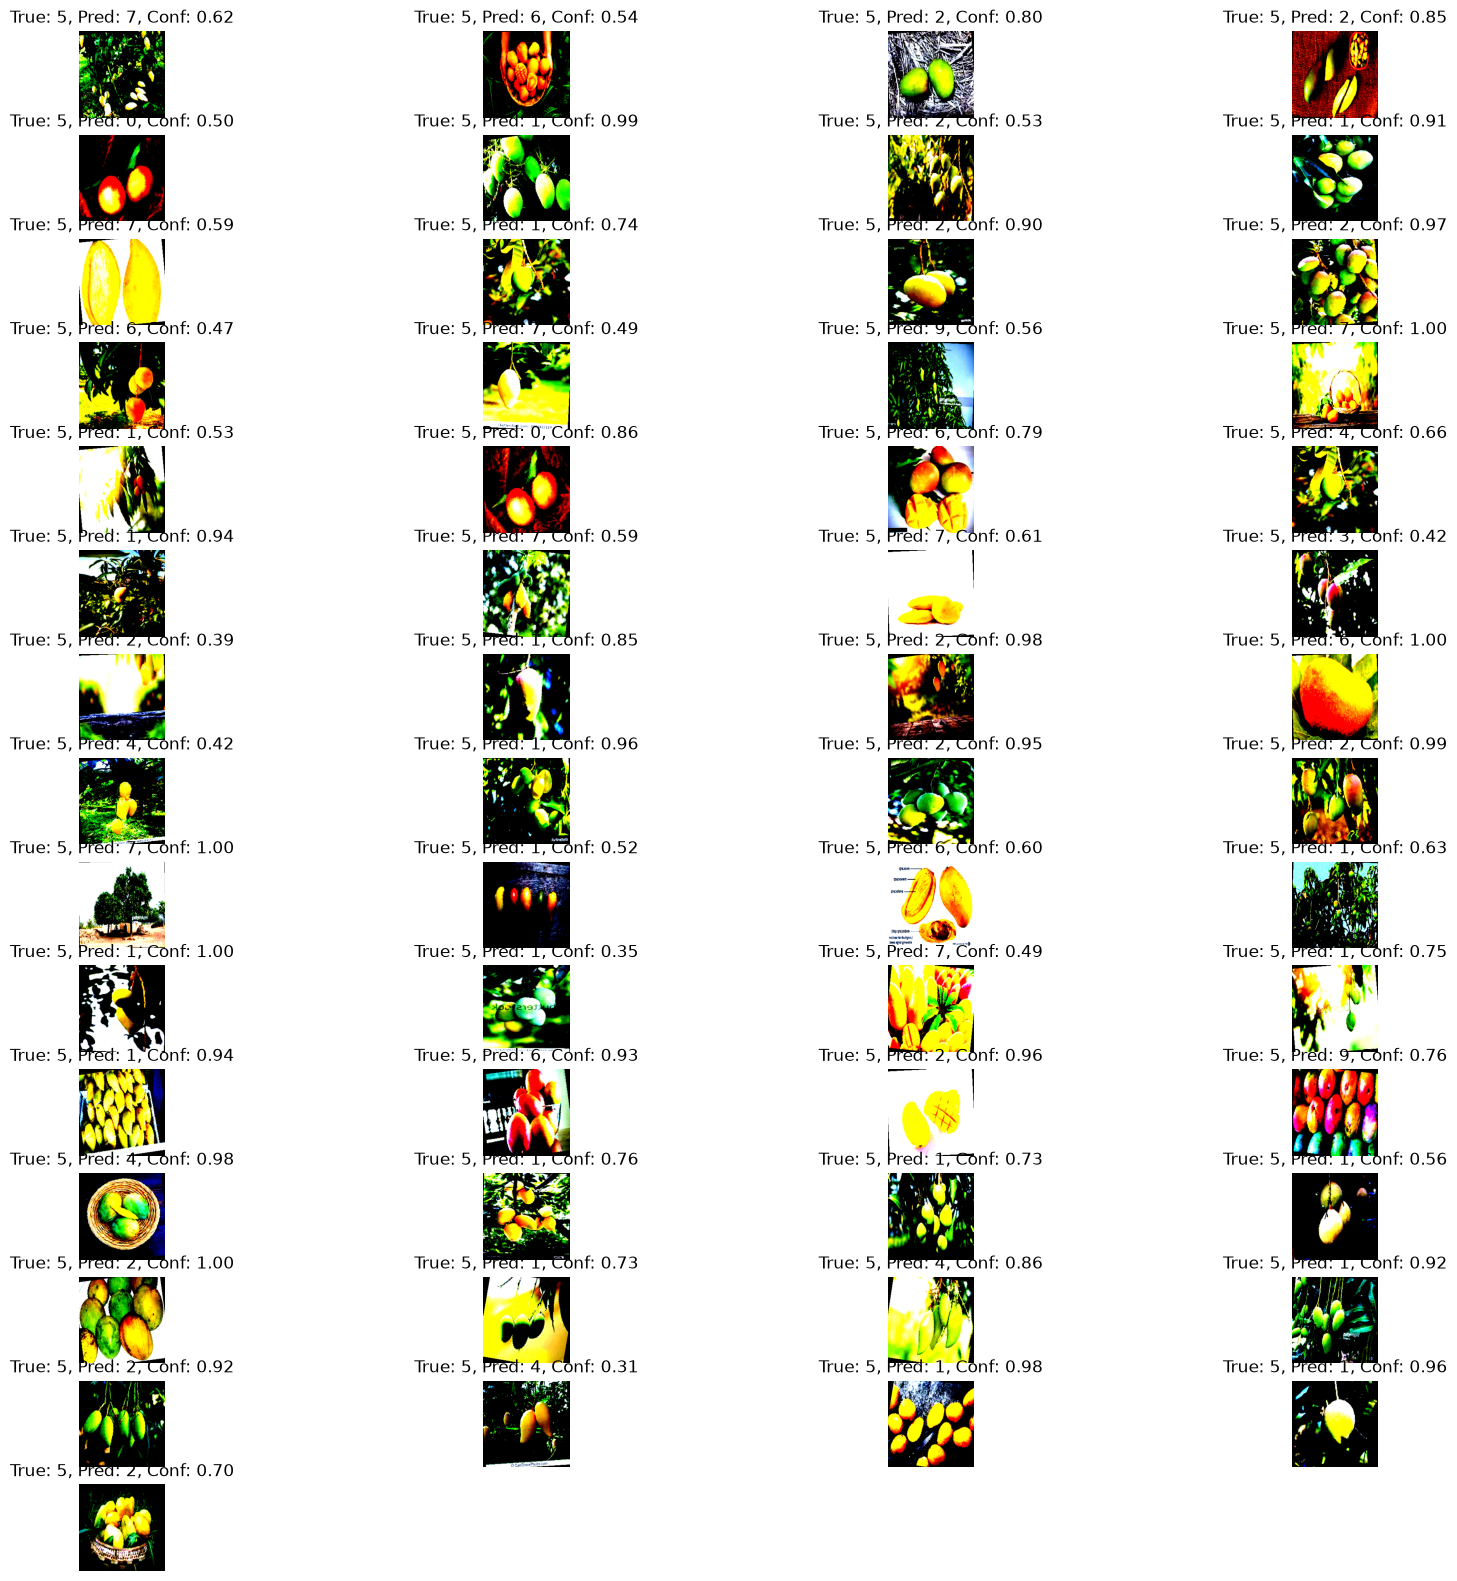

In [256]:
plt.figure(figsize=(20, 20))
# hiển thị ảnh dự đoán sai

idx_class = 5

confusion_pd = pd.DataFrame({'images': images_list, 'preds': preds_list, 'labels': labels_list, 'confidence': confidence_list})
confusion_pd = confusion_pd[confusion_pd['labels'] != confusion_pd['preds']].sort_values(by='labels')
# display(confusion_pd)
i = 0
count_class = confusion_pd[confusion_pd['labels'] == idx_class].shape[0]
print(f"Số lượng ảnh dự đoán sai của class {idx_class}: {count_class}")
for img, label, pred, conf in confusion_pd[['images', 'labels', 'preds', 'confidence']].values:
        if label != idx_class:
            continue
        i += 1
        if i > count_class:
            break
        plt.subplot(int(count_class/4) + 1, 4, i)
        plt.imshow(img.transpose(1, 2, 0))
        plt.title(f'True: {label}, Pred: {pred}, Conf: {conf:.2f}')
        plt.axis('off')

plt.show()
